# Chronological evaluation and robustness

The heatmap covers the predeclared POS magnitude/duration grid. Delay is conditional on an incremental hit. Archived merchant-day labels are reported separately with no inferred intraday labels.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if not (root / 'config' / 'live_monitoring.v1.json').exists():
    root = root.parent
evidence = root / 'reports' / 'live_monitoring'
figures = evidence / 'figures'
figures.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2, 'figure.dpi': 110})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(figures / (name + '.png'), dpi=140, bbox_inches='tight')
    display(fig)
    plt.close(fig)


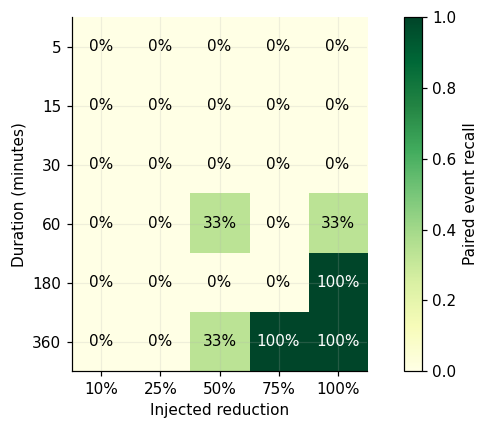

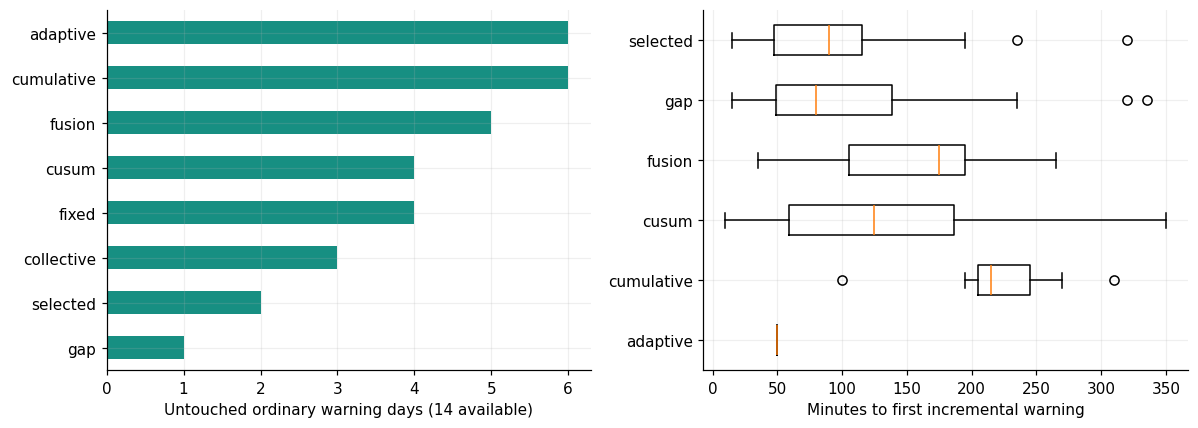

,all_notifications,notifications_per_day,fraction_time_warning
0.5,6.0,0.4286,0.0146
1,7.0,0.5000,0.0171
2,27.0,1.9286,0.0784


,method,days,positive_days,merchant_days_with_warning,overlap_positive_days
0,fixed,280,31,0,0
1,cumulative,280,31,11,11
2,adaptive,280,31,1,1
3,gap,280,31,6,6
4,cusum,280,31,6,6
5,fusion,280,31,4,4
6,selected,280,31,10,10


,events,hits,ordinary_points,ordinary_warning_points
mode,,,,
ar1,1737,777,2644297,184229
raw,1737,537,2644297,866335


In [2]:
s = pd.read_csv(evidence / 'synthetic_cases.csv')
ordinary = json.loads((evidence / 'ordinary_workload.json').read_text())
grid = s[s.method.eq('selected') & s.family.eq('drop')]
p = grid.pivot_table(index='minutes', columns='magnitude', values='hit').sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
m = ax.imshow(p, vmin=0, vmax=1, cmap='YlGn')
ax.set(xticks=range(len(p.columns)), xticklabels=[f'{x:.0%}' for x in p.columns],
       yticks=range(len(p.index)), yticklabels=p.index, xlabel='Injected reduction', ylabel='Duration (minutes)')
fig.colorbar(m, ax=ax, label='Paired event recall')
for i in range(len(p.index)):
    for j in range(len(p.columns)):
        ax.text(j, i, f'{p.iloc[i,j]:.0%}', ha='center', va='center',
                color='white' if p.iloc[i,j] >= .6 else 'black')
save(fig, 'pos_duration_and_intensity')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
burden = pd.Series(ordinary['method_warning_days']).sort_values()
burden.plot.barh(ax=axes[0], color='#178f82')
axes[0].set(xlabel='Untouched ordinary warning days (14 available)')
delays = s[s.hit].groupby('method').delay
groups = [(name, x.dropna().tolist()) for name, x in delays if x.notna().any()]
if groups:
    axes[1].boxplot([x for _, x in groups], vert=False)
    axes[1].set_yticks(range(1, len(groups) + 1), [k for k, _ in groups])
axes[1].set(xlabel='Minutes to first incremental warning')
save(fig, 'workload_and_detection_delay')
budgets = pd.DataFrame(ordinary['budget_sensitivity']).T
display(budgets[['all_notifications','notifications_per_day','fraction_time_warning']].round(4))
display(pd.read_json(evidence / 'development_overlap.json'))
external = evidence / 'external_aiops.json'
if external.exists():
    display(pd.read_json(external).groupby('mode')[['events','hits','ordinary_points','ordinary_warning_points']].sum())
